# Problem 2 – Part 3: Sentiment Model (DistilBERT, Weighted Loss) — نسخه‌ی اصلاح‌شده
پیش‌بینی امتیاز ۱ تا ۵ از روی متن نظر با **DistilBERT** (fine-tune شده برای این مسئله).

**تغییرات نسبت به نسخه‌ی قبل**
- تعریف `MOUNT_DRIVE` و `DATA_DIR` (قبلاً تعریف نشده بودند) و نام فایل خروجی مطابق صفحه‌ی پروژه: `q2_submission.csv`
- پاک‌سازی بهتر متن (`html.unescape`، حذف تگ/لینک، کوتاه کردن حروف تکراری، مقدار خالی امن)
- ورودی ساخت‌یافته با `summary` کوتاه‌شده و (اختیاری) برند/عنوان محصول، بدون باگ `"nan"`
- حذف ردیف‌های بدون متن نظر **فقط در train** (در test هیچ ردیفی حذف نمی‌شود)
- دو validation: **طبیعی** و **متوازن** (انتخاب مدل روی متوازن، چون توزیع test احتمالاً متوازن‌تر از train است)
- بررسی هم‌پوشانی `asin` بین train / validation / test
- بخش (اختیاری) ablation برای انتخاب `WEIGHT_POWER`
- تحلیل سه‌کلاسه (منفی / خنثی / مثبت) روی پیش‌بینی‌های ۵ کلاسه

قبل از اجرا: `Runtime > Change runtime type > T4 GPU`

## 1. Install & Imports

In [ ]:
!pip -q install -U transformers datasets accelerate gdown scikit-learn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [ ]:
import os, re, html, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gdown
import torch
import torch.nn.functional as F
from datasets import Dataset
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, TrainingArguments, Trainer, set_seed)

SEED = 42
set_seed(SEED)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NOT AVAILABLE - enable GPU runtime!")

GPU: Tesla T4


## 2. Configuration
همه‌ی تنظیمات مهم یک‌جا هستند.

- `WEIGHT_POWER`: ۰ = بدون وزن، ۰.۵ = ملایم، ۱ = کاملاً متوازن. مقدار پیش‌فرض ۰.۵ است (در صورت اجرای ablation در بخش ۹ می‌توان آن را از روی نتیجه تغییر داد).
- `USE_PRODUCT_INFO`: اضافه کردن برند و عنوان محصول به ورودی (با ablation بسنجید؛ از بودجه‌ی توکن مصرف می‌کند).

In [ ]:
# ---------- Data ----------
N_TRAIN = 250_000            # تعداد نمونه‌ی آموزش (از ~840k). None = همه
VAL_NATURAL_SIZE = 20_000    # validation با توزیع طبیعی (مثل train)
VAL_BAL_PER_CLASS = 1_500    # validation متوازن: تعداد نمونه در هر کلاس
USE_SUMMARY = True
USE_PRODUCT_INFO = False     # برند + عنوان محصول
SUMMARY_MAX_WORDS = 40
TITLE_MAX_WORDS = 15

# ---------- Model ----------
MODEL_NAME = "distilbert-base-uncased"
MAX_LEN = 256
WEIGHT_POWER = 0.5

# ---------- Training ----------
EPOCHS = 2
TRAIN_BS = 32
EVAL_BS = 128
LR = 2e-5

# ---------- Extras ----------
RUN_ABLATION = False         # True = مقایسه‌ی WEIGHT_POWER روی زیرمجموعه‌ی کوچک (حدود ۳۰-۴۰ دقیقه)
ABLATION_POWERS = [0.0, 0.5, 1.0]
ABLATION_N = 50_000

# ---------- Paths ----------
MOUNT_DRIVE = True
DATA_DIR = "/content/data"
SUBMISSION_NAME = "q2_submission.csv"   # نام فایل طبق صفحه‌ی پروژه

os.makedirs(DATA_DIR, exist_ok=True)
if MOUNT_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUTPUT_DIR = "/content/drive/MyDrive/distilbert_reviews"
    except Exception as e:
        print("Drive mount failed, using local storage instead:", e)
        OUTPUT_DIR = "/content/distilbert_reviews"
else:
    OUTPUT_DIR = "/content/distilbert_reviews"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Data dir:", DATA_DIR, "| Output dir:", OUTPUT_DIR)

Drive mount failed, using local storage instead: Error: credential propagation was unsuccessful
Data dir: /content/data | Output dir: /content/distilbert_reviews


## 3. Download Datasets (train / test / title_brand)
نقش هر فایل از روی ستون‌هایش تشخیص داده می‌شود (`overall` → train، `title`/`brand` → title_brand، بقیه → test)، پس ترتیب لینک‌ها مهم نیست.

In [ ]:
FILE_IDS = [
    "1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW",
    "1I9aPAvvYgQWdHGKtnd7IeTGXpx8vOm4h",
    "1-8TsrqTRFP-q9TM-6HinhO0ZVXFHq9TB",
]

raw_paths = []
for i, fid in enumerate(FILE_IDS):
    path = f"{DATA_DIR}/raw_{i}.csv"
    if not os.path.exists(path):
        gdown.download(id=fid, output=path, quiet=False)
    raw_paths.append(path)

paths = {}
for p in raw_paths:
    cols = set(pd.read_csv(p, nrows=2).columns)
    if "overall" in cols:
        paths["train"] = p
    elif {"title", "brand"} & cols:
        paths["title_brand"] = p
    else:
        paths["test"] = p

assert set(paths) == {"train", "test", "title_brand"}, f"Could not identify files: {paths}"
print(paths)

Downloading...
From (original): https://drive.google.com/uc?id=1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW
From (redirected): https://drive.google.com/uc?id=1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW&confirm=t&uuid=7dc5dd5e-9086-4e94-bd52-4a86b7ebf75b
To: /content/data/raw_0.csv
100%|██████████| 635M/635M [00:25<00:00, 25.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=1I9aPAvvYgQWdHGKtnd7IeTGXpx8vOm4h
To: /content/data/raw_1.csv
100%|██████████| 97.3M/97.3M [00:05<00:00, 18.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=1-8TsrqTRFP-q9TM-6HinhO0ZVXFHq9TB
To: /content/data/raw_2.csv
100%|██████████| 15.6M/15.6M [00:01<00:00, 11.8MB/s]

{'train': '/content/data/raw_0.csv', 'title_brand': '/content/data/raw_1.csv', 'test': '/content/data/raw_2.csv'}


## 4. Load & Merge
`title_brand` شامل `asin` تکراری است؛ قبل از merge تکراری‌ها حذف می‌شوند تا ردیف‌ها زیاد نشوند. ترتیب ردیف‌های test با merge از نوع `left` حفظ می‌شود (برای فایل submission ضروری است).

In [ ]:
train_cols = ["overall", "reviewText", "summary", "asin"]
test_cols = ["reviewText", "summary", "asin"]

train_all = pd.read_csv(paths["train"], usecols=train_cols, low_memory=False)
test_data = pd.read_csv(paths["test"], usecols=test_cols, low_memory=False)
title_brand = pd.read_csv(paths["title_brand"])

print("train:", train_all.shape, "| test:", test_data.shape, "| title_brand:", title_brand.shape)

title_brand_unique = title_brand.drop_duplicates(subset="asin", keep="first")[["asin", "title", "brand"]]

n_train, n_test = len(train_all), len(test_data)
train_all = train_all.merge(title_brand_unique, on="asin", how="left")
test_data = test_data.merge(title_brand_unique, on="asin", how="left")
assert len(train_all) == n_train and len(test_data) == n_test, "Merge changed the number of rows!"
print("Merge OK:", train_all.shape, test_data.shape)
train_all.head()

train: (838944, 4) | test: (20000, 3) | title_brand: (786445, 3)
Merge OK: (838944, 6) (20000, 5)


,overall,asin,reviewText,summary,title,brand
0,2,0511189877,I have an older URC-WR7 remote and thought thi...,Cannot Learn,CLIKR-5 Time Warner Cable Remote Control UR5U-...,URC
1,5,0511189877,First time I've EVER had a remote that needed ...,zero programming needed! Miracle!?,CLIKR-5 Time Warner Cable Remote Control UR5U-...,URC
2,4,0511189877,Got them and only 2 of them worked. company ca...,Works Good and programs easy.,CLIKR-5 Time Warner Cable Remote Control UR5U-...,URC
3,5,0511189877,I got tired of the remote being on the wrong s...,Same as TWC remote,CLIKR-5 Time Warner Cable Remote Control UR5U-...,URC
4,5,0594459451,After purchasing cheap cords from another webs...,Good Quality Cord,Barnes &amp; Noble Nook Color Tablet USB Cable...,Barnes &amp; Noble


## 5. Preprocessing (مناسب DistilBERT)
برای ترنسفورمرها **نباید** stopword حذف شود، lemmatization انجام شود یا علائم نگارشی پاک شوند؛ چون مدل از کلمات نفی (`not`, `no`) و حتی علائمی مثل `!` برای فهم احساس استفاده می‌کند و tokenizer مخصوص خودش را دارد. فقط **نویز** را پاک می‌کنیم:

- تبدیل HTML entity ها (`&amp;`) و حذف تگ‌های HTML
- حذف لینک‌ها
- کوتاه کردن حروف تکراری اغراق‌آمیز (`sooooo` → `sooo`)
- یکدست کردن فاصله‌ها
- مقدار خالی (NaN) → رشته‌ی خالی (جلوگیری از رشته‌ی `"nan"` در ورودی)

lowercase دستی لازم نیست چون tokenizer مدل `uncased` است.

In [ ]:
URL_RE = re.compile(r"http\S+|www\.\S+")
TAG_RE = re.compile(r"<[^>]+>")
REPEAT_RE = re.compile(r"(.)\1{3,}")
WS_RE = re.compile(r"\s+")

def clean_text(text):
    if not isinstance(text, str):          # NaN / None -> ""
        return ""
    text = html.unescape(text)
    text = TAG_RE.sub(" ", text)
    text = URL_RE.sub(" ", text)
    text = REPEAT_RE.sub(r"\1\1\1", text)
    return WS_RE.sub(" ", text).strip()

def truncate_words(text, n):
    return " ".join(text.split()[:n])

for e in ["Love it!!! soooooooo good &amp; cheap <br /> see http://abc.com", "NOT worth it...", None, float("nan")]:
    print(repr(e), "->", repr(clean_text(e)))

'Love it!!! soooooooo good &amp; cheap <br /> see http://abc.com' -> 'Love it!!! sooo good & cheap see'
'NOT worth it...' -> 'NOT worth it...'
None -> ''
nan -> ''


In [ ]:
def prepare_text_columns(df):
    """ساخت دو بخش ورودی: head (برند | عنوان | summary) و review (متن اصلی نظر)."""
    out = pd.DataFrame(index=df.index)
    out["review"] = df["reviewText"].map(clean_text)

    pieces = []
    if USE_PRODUCT_INFO:
        pieces.append(df["brand"].map(clean_text))
        pieces.append(df["title"].map(clean_text).map(lambda s: truncate_words(s, TITLE_MAX_WORDS)))
    if USE_SUMMARY:
        pieces.append(df["summary"].map(clean_text).map(lambda s: truncate_words(s, SUMMARY_MAX_WORDS)))

    if pieces:
        out["head"] = [" | ".join(p for p in row if p) for row in zip(*pieces)]
    else:
        out["head"] = ""
    return out

## 6. Splits
ترتیب جداسازی:
1. **validation متوازن** (به تعداد برابر از هر کلاس)
2. **validation طبیعی** (توزیع مشابه train)
3. **train** (نمونه‌برداری stratified از باقی‌مانده)

سه مجموعه از هم جدا هستند. ردیف‌های بدون متن نظر فقط از train حذف می‌شوند.

In [ ]:
train_all = train_all.dropna(subset=["overall"]).reset_index(drop=True)
train_all["overall"] = train_all["overall"].astype(int)

print("Full train distribution (%):")
print((train_all["overall"].value_counts(normalize=True).sort_index() * 100).round(2).to_string())

# 1) balanced validation
val_bal_df = train_all.groupby("overall", group_keys=False).sample(n=VAL_BAL_PER_CLASS, random_state=SEED)
remaining = train_all.drop(val_bal_df.index)

# 2) natural validation
val_nat_df = remaining.sample(n=VAL_NATURAL_SIZE, random_state=SEED)
remaining = remaining.drop(val_nat_df.index)

# 3) train (stratified subsample)
if N_TRAIN is not None and N_TRAIN < len(remaining):
    train_df = remaining.groupby("overall", group_keys=False).sample(frac=N_TRAIN / len(remaining), random_state=SEED)
else:
    train_df = remaining
train_df = train_df.sample(frac=1, random_state=SEED).reset_index(drop=True)
val_bal_df = val_bal_df.reset_index(drop=True)
val_nat_df = val_nat_df.reset_index(drop=True)

del remaining, train_all
gc.collect()
print("\ntrain:", len(train_df), "| val_balanced:", len(val_bal_df), "| val_natural:", len(val_nat_df), "| test:", len(test_data))

Full train distribution (%):
overall
1     9.89
2     6.77
3     9.68
4    18.66
5    55.01

train: 249999 | val_balanced: 7500 | val_natural: 20000 | test: 20000


In [ ]:
train_txt = prepare_text_columns(train_df)
val_bal_txt = prepare_text_columns(val_bal_df)
val_nat_txt = prepare_text_columns(val_nat_df)
test_txt = prepare_text_columns(test_data)          # هیچ ردیفی حذف نمی‌شود

# برچسب ۱..۵ -> ۰..۴
train_txt["labels"] = train_df["overall"].values - 1
val_bal_txt["labels"] = val_bal_df["overall"].values - 1
val_nat_txt["labels"] = val_nat_df["overall"].values - 1

# حذف ردیف‌های بدون متن نظر، فقط از train
n_before = len(train_txt)
train_txt = train_txt[train_txt["review"] != ""].reset_index(drop=True)
print(f"Dropped {n_before - len(train_txt)} empty-review rows from train")

print("\nTrain label distribution (%):")
print((train_txt["labels"].add(1).value_counts(normalize=True).sort_index() * 100).round(2).to_string())

for i in range(3):
    print(f"\n[label={train_txt.loc[i, 'labels'] + 1}] HEAD: {train_txt.loc[i, 'head']}\n   REVIEW: {train_txt.loc[i, 'review'][:150]}")

Dropped 1 empty-review rows from train

Train label distribution (%):
labels
1     9.80
2     6.63
3     9.60
4    18.64
5    55.33

[label=2] HEAD: Really wish the apps and whatnot were NOT from yahoo and it was NOT vizio based because while for the price it was super competi
   REVIEW: I mean it's a TV but we bought it during the "smartTV" fad. Really wish the apps and whatnot were NOT from yahoo and it was NOT vizio based because wh

[label=3] HEAD: Prepare for a learning curve
   REVIEW: A serious learning curve the camera seems to have decent build quality the memory card is hard to remove if you can even find it. (it is there just bl

[label=1] HEAD: Garbage
   REVIEW: The connection to the phone is so loose it will not stay in. The slightest bump and it falls out. Charging is extremely slow. I bought these for the c


### بررسی هم‌پوشانی محصولات (`asin`)
اگر بخش بزرگی از نمونه‌های validation/test محصولی دارند که در train هم هست، مدل می‌تواند «محصول» را حفظ کند و validation خوش‌بین می‌شود (به‌ویژه وقتی برند/عنوان در ورودی باشد).

In [ ]:
train_asins = set(train_df["asin"])
for name, d in [("val_balanced", val_bal_df), ("val_natural", val_nat_df), ("test", test_data)]:
    print(f"{name:13s}: {d['asin'].isin(train_asins).mean():.1%} of rows have an asin seen in train")

val_balanced : 89.1% of rows have an asin seen in train
val_natural  : 89.4% of rows have an asin seen in train
test         : 88.8% of rows have an asin seen in train


## 7. Tokenization
padding دینامیک (هر batch تا طول بلندترین نمونه‌ی خودش) برای سرعت بیشتر؛ ورودی به‌صورت جفت‌متن `[CLS] head [SEP] review [SEP]`. هنگام برش، بخش بلندتر (معمولاً review) کوتاه می‌شود.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
USE_PAIR = USE_SUMMARY or USE_PRODUCT_INFO

def tokenize_fn(batch):
    if USE_PAIR:
        return tokenizer(batch["head"], batch["review"], truncation=True, max_length=MAX_LEN)
    return tokenizer(batch["review"], truncation=True, max_length=MAX_LEN)

def to_hf_dataset(df):
    ds = Dataset.from_pandas(df.reset_index(drop=True), preserve_index=False)
    return ds.map(tokenize_fn, batched=True, remove_columns=["head", "review"], desc="Tokenizing")

train_ds = to_hf_dataset(train_txt)
val_bal_ds = to_hf_dataset(val_bal_txt)
val_nat_ds = to_hf_dataset(val_nat_txt)
test_ds = to_hf_dataset(test_txt)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
print(train_ds)

lens = np.array([len(x) for x in train_ds.select(range(min(5000, len(train_ds))))["input_ids"]])
print(f"Token length (sample): median={np.median(lens):.0f}, 95th pct={np.percentile(lens, 95):.0f}, "
      f"truncated at {MAX_LEN}: {np.mean(lens >= MAX_LEN):.1%}")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizing:   0%|          | 0/249998 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/7500 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/20000 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/20000 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 249998
})
Token length (sample): median=105, 95th pct=256, truncated at 256: 12.8%


## 8. Class Weights, Model & Weighted Trainer
چون بیشتر داده‌ها ۵ ستاره است، به‌جای حذف داده‌ها (undersampling) به loss وزن می‌دهیم:

$w_c = \left(\frac{N}{K \cdot n_c}\right)^{p}$  که `p = WEIGHT_POWER`

وزن‌ها طوری نرمال می‌شوند که میانگین وزن نمونه‌ها ۱ باشد. تابع `build_trainer` برای هر مقدار `p` یک مدل تازه می‌سازد تا هم آموزش اصلی و هم ablation از یک کد استفاده کنند.

In [ ]:
def compute_class_weights(labels, power):
    counts = np.bincount(np.asarray(labels), minlength=5)
    N, K = counts.sum(), 5
    w = (N / (K * counts)) ** power
    w = w / (w * counts).sum() * N          # میانگین وزنی نمونه‌ها = 1
    return counts, w

class WeightedTrainer(Trainer):
    """Trainer با Cross-Entropy وزن‌دار."""
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss = F.cross_entropy(logits.float(), labels, weight=self.class_weights.to(logits.device))
        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_micro": f1_score(labels, preds, average="micro"),   # معیار نهایی پروژه
        "f1_macro": f1_score(labels, preds, average="macro"),
    }

def build_trainer(weight_power, train_dataset, epochs, output_dir, ablation=False):
    _, w = compute_class_weights(list(train_dataset["labels"]), weight_power)
    class_weights = torch.tensor(w, dtype=torch.float32)

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=5,
        id2label={i: str(i + 1) for i in range(5)}, label2id={str(i + 1): i for i in range(5)})

    steps_per_epoch = -(-len(train_dataset) // TRAIN_BS)
    args = TrainingArguments(
        output_dir=output_dir,
        num_train_epochs=epochs,
        per_device_train_batch_size=TRAIN_BS,
        per_device_eval_batch_size=EVAL_BS,
        learning_rate=LR,
        weight_decay=0.01,
        warmup_steps=int(0.06 * steps_per_epoch * epochs),
        lr_scheduler_type="linear",
        eval_strategy="no" if ablation else "epoch",
        save_strategy="no" if ablation else "epoch",
        save_total_limit=2,
        load_best_model_at_end=not ablation,
        metric_for_best_model="f1_micro",     # روی validation متوازن
        greater_is_better=True,
        fp16=torch.cuda.is_available(),
        dataloader_num_workers=2,
        logging_steps=200,
        report_to="none",
        seed=SEED,
    )
    return WeightedTrainer(
        model=model, args=args, train_dataset=train_dataset,
        eval_dataset=None if ablation else val_bal_ds,
        processing_class=tokenizer, data_collator=data_collator,
        compute_metrics=compute_metrics, class_weights=class_weights)

def predict_probs(trainer, ds):
    out = trainer.predict(ds)
    probs = torch.softmax(torch.tensor(out.predictions, dtype=torch.float32), dim=-1).numpy()
    labels = None if out.label_ids is None else out.label_ids + 1
    return probs, labels

## 9. (اختیاری) Ablation روی `WEIGHT_POWER`
با `RUN_ABLATION = True` سه مقدار وزن‌دهی روی یک زیرمجموعه‌ی کوچک (۱ epoch) مقایسه می‌شود. مقایسه روی **هر دو validation** انجام می‌شود:
- validation متوازن ≈ شرایط احتمالی test
- validation طبیعی ≈ توزیع train

در این اجرا ablation انجام نشد و `WEIGHT_POWER = 0.5` استفاده شد.

In [ ]:
if RUN_ABLATION:
    sub = train_ds.shuffle(seed=SEED).select(range(min(ABLATION_N, len(train_ds))))
    rows = []
    for p in ABLATION_POWERS:
        tr = build_trainer(p, sub, epochs=1, output_dir=f"{OUTPUT_DIR}/ablation_p{p}", ablation=True)
        tr.train()
        for name, ds in [("balanced", val_bal_ds), ("natural", val_nat_ds)]:
            probs, y = predict_probs(tr, ds)
            pred = probs.argmax(1) + 1
            rows.append({"weight_power": p, "val": name,
                         "micro_f1": f1_score(y, pred, average="micro"),
                         "macro_f1": f1_score(y, pred, average="macro")})
        del tr
        gc.collect(); torch.cuda.empty_cache()
    ablation_df = pd.DataFrame(rows).round(4)
    display(ablation_df.pivot(index="weight_power", columns="val", values=["micro_f1", "macro_f1"]))
else:
    print("Ablation skipped (RUN_ABLATION=False)")

Ablation skipped (RUN_ABLATION=False)


## 10. Train
اگر Colab قطع شد، با `trainer.train(resume_from_checkpoint=True)` از آخرین چک‌پوینت ذخیره‌شده ادامه دهید. بهترین checkpoint بر اساس micro-F1 روی **validation متوازن** انتخاب می‌شود.

In [14]:
counts, w = compute_class_weights(list(train_ds["labels"]), WEIGHT_POWER)
print(pd.DataFrame({"rating": range(1, 6), "count": counts, "weight": w.round(3)}).to_string(index=False))

trainer = build_trainer(WEIGHT_POWER, train_ds, EPOCHS, OUTPUT_DIR)
trainer.train()

 rating  count  weight
      1  24491   1.554
      2  16579   1.889
      3  24001   1.570
      4  46593   1.127
      5 138334   0.654


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Micro,F1 Macro
1,0.724979,0.811754,0.650533,0.650533,0.645174


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Accuracy,F1 Micro,F1 Macro
1,0.724979,0.811754,0.650533,0.650533,0.645174
2,0.633493,0.816234,0.654533,0.654533,0.648783


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=15626, training_loss=0.7403830294265464, metrics={'train_runtime': 3048.6619, 'train_samples_per_second': 164.005, 'train_steps_per_second': 5.126, 'total_flos': 3.308254698159648e+16, 'train_loss': 0.7403830294265464, 'epoch': 2.0})

## 11. Evaluation (validation متوازن و طبیعی)

=== validation BALANCED ===
micro-F1 (= accuracy): 0.6545
macro-F1:              0.6488

              precision    recall  f1-score   support

           1      0.696     0.750     0.722      1500
           2      0.566     0.512     0.537      1500
           3      0.584     0.551     0.567      1500
           4      0.653     0.571     0.609      1500
           5      0.741     0.889     0.808      1500

    accuracy                          0.655      7500
   macro avg      0.648     0.655     0.649      7500
weighted avg      0.648     0.655     0.649      7500



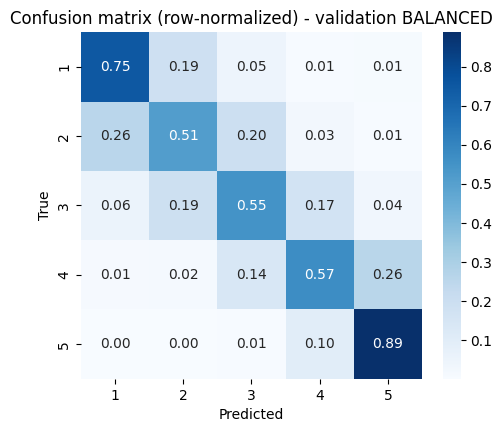

=== validation NATURAL ===
micro-F1 (= accuracy): 0.7562
macro-F1:              0.6492

              precision    recall  f1-score   support

           1      0.729     0.766     0.747      1958
           2      0.483     0.479     0.481      1443
           3      0.506     0.565     0.534      1836
           4      0.593     0.594     0.593      3782
           5      0.904     0.879     0.891     10981

    accuracy                          0.756     20000
   macro avg      0.643     0.656     0.649     20000
weighted avg      0.761     0.756     0.758     20000



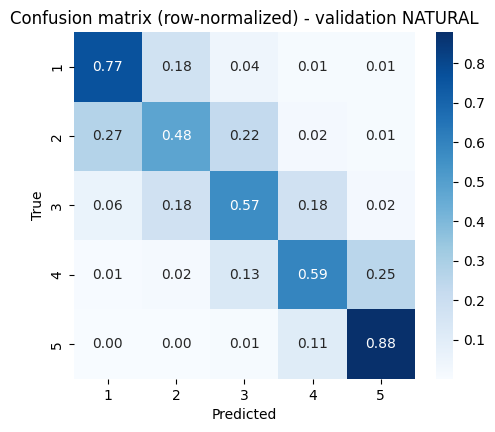

In [15]:
def report(name, y_true, y_pred):
    print(f"=== {name} ===")
    print(f"micro-F1 (= accuracy): {f1_score(y_true, y_pred, average='micro'):.4f}")
    print(f"macro-F1:              {f1_score(y_true, y_pred, average='macro'):.4f}\n")
    print(classification_report(y_true, y_pred, digits=3))
    cm = confusion_matrix(y_true, y_pred, normalize="true")
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=range(1, 6), yticklabels=range(1, 6))
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Confusion matrix (row-normalized) - {name}")
    plt.show()

probs_bal, y_bal = predict_probs(trainer, val_bal_ds)
probs_nat, y_nat = predict_probs(trainer, val_nat_ds)

report("validation BALANCED", y_bal, probs_bal.argmax(1) + 1)
report("validation NATURAL", y_nat, probs_nat.argmax(1) + 1)

### تحلیل سه‌کلاسه (منفی / خنثی / مثبت)
مدل همچنان ۵ کلاسه است (طبق صورت پروژه)؛ فقط پیش‌بینی‌ها برای تحلیل به سه گروه تبدیل می‌شوند: ۱ و ۲ → منفی، ۳ → خنثی، ۴ و ۵ → مثبت. همچنین سهم خطاهای «مجاور» (اختلاف یک ستاره) محاسبه می‌شود.

[balanced] 5-class acc: 0.6545 | 3-class acc: 0.8151 | share of errors that are off by one star: 86.8%
[natural] 5-class acc: 0.7562 | 3-class acc: 0.8989 | share of errors that are off by one star: 88.7%


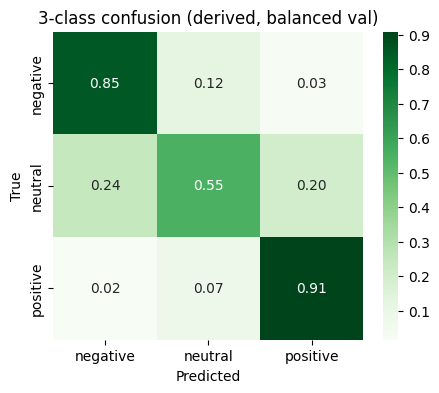

In [16]:
to3 = np.array([0, 0, 0, 1, 2, 2])   # index = rating (1..5)
names3 = ["negative", "neutral", "positive"]

for name, probs, y in [("balanced", probs_bal, y_bal), ("natural", probs_nat, y_nat)]:
    pred = probs.argmax(1) + 1
    err = pred != y
    adj = (np.abs(pred - y) == 1)[err].mean() if err.any() else float("nan")
    print(f"[{name}] 5-class acc: {accuracy_score(y, pred):.4f} | 3-class acc: {accuracy_score(to3[y], to3[pred]):.4f} "
          f"| share of errors that are off by one star: {adj:.1%}")

cm3 = confusion_matrix(to3[y_bal], to3[probs_bal.argmax(1) + 1], normalize="true")
plt.figure(figsize=(5, 4))
sns.heatmap(cm3, annot=True, fmt=".2f", cmap="Greens", xticklabels=names3, yticklabels=names3)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("3-class confusion (derived, balanced val)")
plt.show()

## 12. Prediction on Test Data & Submission File
- ردیف‌های test بدون حذف و با همان ترتیب اصلی پیش‌بینی می‌شوند.
- فایل خروجی: `q2_submission.csv`، یک ستون `predicted` با مقادیر ۱ تا ۵، **بدون index**.

In [17]:
# پیش‌بینی روی test (بدون حذف ردیف و با همان ترتیب اصلی)
probs_test, _ = predict_probs(trainer, test_ds)
test_pred = probs_test.argmax(1) + 1

submission = pd.DataFrame({"predicted": test_pred})
assert len(submission) == len(test_data), "Row count mismatch with test set!"
assert submission["predicted"].between(1, 5).all(), "Predictions must be in 1..5"

submission.to_csv(SUBMISSION_NAME, index=False)
submission.to_csv(f"{OUTPUT_DIR}/{SUBMISSION_NAME}", index=False)   # نسخه‌ی پشتیبان
print(f"Saved {SUBMISSION_NAME}")
print(submission["predicted"].value_counts(normalize=True).sort_index().round(3).to_string())
submission.head()

Saved q2_submission.csv
predicted
1    0.218
2    0.171
3    0.194
4    0.179
5    0.237


,predicted
0,1
1,1
2,1
3,1
4,1


In [18]:
try:
    from google.colab import files
    files.download(SUBMISSION_NAME)
except Exception as e:
    print("Download manually from the file browser:", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Save Model

In [19]:
final_dir = f"{OUTPUT_DIR}/final_model"
trainer.save_model(final_dir)
tokenizer.save_pretrained(final_dir)
print("Saved to", final_dir)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to /content/distilbert_reviews/final_model


## چک‌لیست قبل از ارسال
- [ ] نام فایل خروجی با صفحه‌ی پروژه یکی است (`q2_submission.csv`) و ستون `predicted` بدون index دارد
- [ ] `WEIGHT_POWER = 0.5` (وزن ملایم) انتخاب شد؛ دلیل: وزن کامل ممکن است دقت روی کلاس‌های پرتعداد را کم کند
- [ ] نتیجه‌ی validation متوازن و طبیعی هر دو گزارش شده‌اند
- [ ] اعضای گروه معماری DistilBERT، WordPiece، `[CLS]`/`[SEP]` و loss وزن‌دار را می‌توانند توضیح دهند